## 1. Environment and configuration

In [ ]:
# Imports
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from torchvision import models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import confusion_matrix

import seaborn as sns

print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# --------------------------------------------------
# Dataset paths
# --------------------------------------------------

CAMVID_ROOT = Path(
    "/content/drive/MyDrive/AAI-521/project/datasets/camvid"
)

IMAGE_DIR = CAMVID_ROOT / "images"
ORIGINAL_MASK_DIR = CAMVID_ROOT / "masks"
BLUECHANNEL_MASK_DIR = CAMVID_ROOT / "bluechannel"

PREPROCESSED_DIR = CAMVID_ROOT / "preprocessed"

MASTER_METADATA_PATH = (
    PREPROCESSED_DIR / "camvid_preprocessed_metadata.csv"
)

ACTIVE_CLASSES_PATH = (
    PREPROCESSED_DIR / "active_classes.csv"
)

# --------------------------------------------------
# Output paths
# --------------------------------------------------

IMPROVED_MODEL_DIR = (
    CAMVID_ROOT / "models" / "improved_unet_resnet18"
)

IMPROVED_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    IMPROVED_MODEL_DIR / "best_unet_resnet18.pth"
)

# --------------------------------------------------
# Reproducibility
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --------------------------------------------------
# Dataset configuration
# --------------------------------------------------

IMAGE_WIDTH = 320
IMAGE_HEIGHT = 240

IMAGE_SIZE = (IMAGE_WIDTH, IMAGE_HEIGHT)

NUM_CLASSES = 29
IGNORE_INDEX = 255

BATCH_SIZE = 8
NUM_WORKERS = 2

# ImageNet normalization for pretrained ResNet-18
IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]

# --------------------------------------------------
# Training configuration
# --------------------------------------------------

NUM_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 7

ENCODER_LR = 0.0001
DECODER_LR = 0.001

WEIGHT_DECAY = 0.0001

# --------------------------------------------------
# Loss configuration
# --------------------------------------------------

DICE_WEIGHT = 1.0

CLASS_WEIGHT_POWER = 0.5
CLASS_WEIGHT_MIN = 0.5
CLASS_WEIGHT_MAX = 5.0

print("Dataset root:", CAMVID_ROOT)
print("Model output:", IMPROVED_MODEL_DIR)
print("Image dimensions:", IMAGE_SIZE)
print("Number of classes:", NUM_CLASSES)

Dataset root: /content/drive/MyDrive/AAI-521/project/datasets/camvid
Model output: /content/drive/MyDrive/AAI-521/project/datasets/camvid/models/improved_unet_resnet18
Image dimensions: (320, 240)
Number of classes: 29


In [ ]:
# Verify required directories and files

required_paths = [
    IMAGE_DIR,
    ORIGINAL_MASK_DIR,
    BLUECHANNEL_MASK_DIR,
    PREPROCESSED_DIR,
    MASTER_METADATA_PATH,
    ACTIVE_CLASSES_PATH
]

for path in required_paths:
    assert path.exists(), f"Required path not found: {path}"

print("All required paths exist.")

# Load master metadata
master_df = pd.read_csv(MASTER_METADATA_PATH)

# Load active classes
active_classes_df = pd.read_csv(ACTIVE_CLASSES_PATH)

print("\nMaster metadata shape:", master_df.shape)

print("\nMaster metadata columns:")
print(master_df.columns.tolist())

print("\nActive classes:")
display(active_classes_df)

assert "filename" in master_df.columns
assert "split" in master_df.columns
assert "image_path" in master_df.columns
assert "class_name" in active_classes_df.columns

assert len(active_classes_df) == NUM_CLASSES

print("\nMetadata loading successful.")

All required paths exist.

Master metadata shape: (701, 41)

Master metadata columns:
['image', 'filename', 'mask', 'Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall', 'number_of_classes', 'sequence_id', 'split', 'image_path', 'mask_path', 'image_exists', 'mask_exists']

Active classes:


,class_name
0,Road
1,Sky
2,Column_Pole
3,LaneMkgsDriv
4,Building
5,Sidewalk
6,Car
7,Pedestrian
8,Tree
9,Misc_Text



Metadata loading successful.


In [ ]:
# Reconstruct verified source to model label mapping
# Standard CamVid Bluechannel source ordering
SOURCE_CLASS_NAMES = [
    "Animal",
    "Archway",
    "Bicyclist",
    "Bridge",
    "Building",
    "Car",
    "CartLuggagePram",
    "Child",
    "Column_Pole",
    "Fence",
    "LaneMkgsDriv",
    "LaneMkgsNonDriv",
    "Misc_Text",
    "MotorcycleScooter",
    "OtherMoving",
    "ParkingBlock",
    "Pedestrian",
    "Road",
    "RoadShoulder",
    "Sidewalk",
    "SignSymbol",
    "Sky",
    "SUVPickupTruck",
    "TrafficCone",
    "TrafficLight",
    "Train",
    "Tree",
    "Truck_Bus",
    "Tunnel",
    "VegetationMisc",
    "Void",
    "Wall"
]

# Model IDs follow active_classes.csv ordering
CLASS_TO_MODEL_ID = {
    name: idx
    for idx, name in enumerate(
        active_classes_df["class_name"].astype(str).str.strip()
    )
}

# Source ID -> model ID
SOURCE_ID_TO_MODEL_ID = {}

for source_id, class_name in enumerate(
    SOURCE_CLASS_NAMES, start=1
):
    SOURCE_ID_TO_MODEL_ID[source_id] = (
        CLASS_TO_MODEL_ID.get(class_name, IGNORE_INDEX)
    )

# Validate mapping
assert len(CLASS_TO_MODEL_ID) == 29
assert len(SOURCE_ID_TO_MODEL_ID) == 32

assert SOURCE_ID_TO_MODEL_ID[31] == IGNORE_INDEX
assert SOURCE_ID_TO_MODEL_ID[32] == 11

assert sum(
    value != IGNORE_INDEX
    for value in SOURCE_ID_TO_MODEL_ID.values()
) == NUM_CLASSES

mapping_df = pd.DataFrame([
    {
        "source_id": source_id,
        "class_name": class_name,
        "model_id": SOURCE_ID_TO_MODEL_ID[source_id]
    }
    for source_id, class_name in enumerate(
        SOURCE_CLASS_NAMES, start=1
    )
])

display(mapping_df)

print("Source-to-model mapping validation passed.")

,source_id,class_name,model_id
0,1,Animal,24
1,2,Archway,22
2,3,Bicyclist,14
3,4,Bridge,28
4,5,Building,4
5,6,Car,6
6,7,CartLuggagePram,18
7,8,Child,21
8,9,Column_Pole,2
9,10,Fence,15


Source-to-model mapping validation passed.


In [ ]:
#Define Mask conversion function
def convert_source_mask_to_model_mask(source_mask):

    model_mask = np.full(
        source_mask.shape,
        IGNORE_INDEX,
        dtype=np.uint8
    )

    for source_id, model_id in SOURCE_ID_TO_MODEL_ID.items():

        if model_id != IGNORE_INDEX:

            model_mask[
                source_mask == source_id
            ] = model_id

    return model_mask

## 2. Reconstruct the 700-image dataset

In [ ]:
# Build the final segmentation dataset manifest
EXCLUDED_FILENAME = "Seq05VD_f02610"

# Normalize filenames
master_df["filename_stem"] = (
    master_df["filename"]
    .astype(str)
    .apply(lambda x: Path(x).stem)
)

# Find all available Bluechannel masks
bluechannel_files = list(
    BLUECHANNEL_MASK_DIR.rglob("*.png")
)

bluechannel_lookup = {
    p.stem: str(p)
    for p in bluechannel_files
}

# Exclude the officially skipped image
segmentation_df = master_df[
    master_df["filename_stem"] != EXCLUDED_FILENAME
].copy()

# Associate Bluechannel masks
segmentation_df["bluechannel_mask_path"] = (
    segmentation_df["filename_stem"].map(
        bluechannel_lookup
    )
)

# Verify original images
segmentation_df["image_exists"] = (
    segmentation_df["image_path"].apply(
        lambda p: Path(p).exists()
    )
)

# Verify Bluechannel masks
segmentation_df["bluechannel_mask_exists"] = (
    segmentation_df["bluechannel_mask_path"].notna()
)

print("Original metadata rows:", len(master_df))
print("Final segmentation samples:", len(segmentation_df))
print("Available Bluechannel masks:", len(bluechannel_files))

print("\nImage availability:")
print(segmentation_df["image_exists"].value_counts())

print("\nBluechannel mask availability:")
print(segmentation_df["bluechannel_mask_exists"].value_counts())

Original metadata rows: 701
Final segmentation samples: 700
Available Bluechannel masks: 700

Image availability:
image_exists
True    700
Name: count, dtype: int64

Bluechannel mask availability:
bluechannel_mask_exists
True    700
Name: count, dtype: int64


In [ ]:
#Create validation, test and tain splits
train_df = segmentation_df[
    segmentation_df["split"] == "train"
].copy().reset_index(drop=True)

val_df = segmentation_df[
    segmentation_df["split"] == "validation"
].copy().reset_index(drop=True)

test_df = segmentation_df[
    segmentation_df["split"] == "test"
].copy().reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print(
    "Total samples:",
    len(train_df) + len(val_df) + len(test_df)
)

print("\nSequence distribution:")
display(
    pd.crosstab(
        segmentation_df["split"],
        segmentation_df["sequence_id"]
    )
)

Training samples: 406
Validation samples: 170
Test samples: 124
Total samples: 700

Sequence distribution:


sequence_id,0001TP,0006R0,0016E5,Seq05VD
split,,,,
test,124,0,0,0
train,0,101,305,0
validation,0,0,0,170


In [ ]:
# Final dataset integrity validation
assert len(segmentation_df) == 700

assert len(train_df) == 406
assert len(val_df) == 170
assert len(test_df) == 124

assert segmentation_df["filename_stem"].is_unique

assert segmentation_df["image_exists"].all(), (
    "Some image files are missing."
)

assert segmentation_df["bluechannel_mask_exists"].all(), (
    "Some Bluechannel masks are missing."
)

assert segmentation_df["split"].isin(
    ["train", "validation", "test"]
).all()

# Verify no image overlaps between splits
train_ids = set(train_df["filename_stem"])
val_ids = set(val_df["filename_stem"])
test_ids = set(test_df["filename_stem"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Verify the intended sequence separation
assert set(train_df["sequence_id"].unique()) == {
    "0006R0", "0016E5"
}

assert set(val_df["sequence_id"].unique()) == {
    "Seq05VD"
}

assert set(test_df["sequence_id"].unique()) == {
    "0001TP"
}

print("Final dataset integrity validation passed.")

Final dataset integrity validation passed.


## 3. Device Configuration

In [ ]:
# Detect TPU, GPU or CPU
DEVICE_TYPE = None

try:
    import torch_xla
    import torch_xla.core.xla_model as xm

    DEVICE = xm.xla_device()
    DEVICE_TYPE = "TPU"

except ImportError:

    if torch.cuda.is_available():
        DEVICE = torch.device("cuda")
        DEVICE_TYPE = "GPU"

    else:
        DEVICE = torch.device("cpu")
        DEVICE_TYPE = "CPU"

print("Execution device:", DEVICE)
print("Device type:", DEVICE_TYPE)

Execution device: cuda
Device type: GPU


## 4. Improved preprocessing and augmentation

In [ ]:
# Define image normalization
IMAGE_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

IMAGE_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

def normalize_image(image):
    """
    Convert RGB image to normalized float32 representation.
    Input: HWC, uint8
    Output: CHW, float32
    """

    image = image.astype(np.float32) / 255.0

    image = (image - IMAGE_MEAN) / IMAGE_STD

    image = np.transpose(image, (2, 0, 1))

    return torch.from_numpy(
        np.ascontiguousarray(image)
    ).float()

In [ ]:
def augment_image_and_mask(image, mask):

    height, width = mask.shape

    # Horizontal flip
    if random.random() < 0.5:
        image = cv2.flip(image, 1)
        mask = cv2.flip(mask, 1)

    # Small rotation
    if random.random() < 0.5:

        angle = random.uniform(-5.0, 5.0)

        center = (width / 2, height / 2)

        matrix = cv2.getRotationMatrix2D(
            center, angle, 1.0
        )

        image = cv2.warpAffine(
            image,
            matrix,
            (width, height),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )

        mask = cv2.warpAffine(
            mask,
            matrix,
            (width, height),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=IGNORE_INDEX
        )

    # Color augmentation: image only
    image = image.astype(np.float32)

    if random.random() < 0.5:
        alpha = random.uniform(0.85, 1.15)
        image = image * alpha

    if random.random() < 0.5:
        brightness = random.uniform(-20, 20)
        image = image + brightness

    image = np.clip(image, 0, 255).astype(np.uint8)

    return image, mask

In [ ]:
# Implement the improve dataset
class CamVidImprovedDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_size=(320, 240),
        augment=False
    ):

        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load RGB image
        image = cv2.imread(
            str(row["image_path"]),
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise FileNotFoundError(row["image_path"])

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Load Bluechannel mask
        source_mask = cv2.imread(
            str(row["bluechannel_mask_path"]),
            cv2.IMREAD_UNCHANGED
        )

        if source_mask is None:
            raise FileNotFoundError(
                row["bluechannel_mask_path"]
            )

        # Extract class IDs from channel 0
        if source_mask.ndim == 3:
            source_mask = source_mask[:, :, 0]

        # Convert source IDs to model IDs
        model_mask = convert_source_mask_to_model_mask(
            source_mask
        )

        # Resize image and mask
        image = cv2.resize(
            image,
            self.image_size,
            interpolation=cv2.INTER_LINEAR
        )

        model_mask = cv2.resize(
            model_mask,
            self.image_size,
            interpolation=cv2.INTER_NEAREST
        )

        # Apply augmentation only to training data
        if self.augment:
            image, model_mask = augment_image_and_mask(
                image,
                model_mask
            )

        # Normalize image
        image_tensor = normalize_image(image)

        # Convert mask to integer tensor
        mask_tensor = torch.from_numpy(
            np.ascontiguousarray(model_mask)
        ).long()

        return image_tensor, mask_tensor

In [ ]:
# Create dataset objects
train_dataset = CamVidImprovedDataset(
    train_df,
    image_size=IMAGE_SIZE,
    augment=True
)

val_dataset = CamVidImprovedDataset(
    val_df,
    image_size=IMAGE_SIZE,
    augment=False
)

test_dataset = CamVidImprovedDataset(
    test_df,
    image_size=IMAGE_SIZE,
    augment=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 406
Validation samples: 170
Test samples: 124


In [ ]:
# Validate one sample
sample_image, sample_mask = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)

print("Mask shape:", sample_mask.shape)
print("Mask dtype:", sample_mask.dtype)

print("Mask unique IDs:", torch.unique(sample_mask).tolist())

assert sample_image.shape == (3, IMAGE_HEIGHT, IMAGE_WIDTH)
assert sample_mask.shape == (IMAGE_HEIGHT, IMAGE_WIDTH)

assert sample_mask.dtype == torch.long

assert set(torch.unique(sample_mask).tolist()).issubset(
    set(range(NUM_CLASSES)) | {IGNORE_INDEX}
)

print("Improved dataset sample validation passed.")

Image shape: torch.Size([3, 240, 320])
Image dtype: torch.float32
Mask shape: torch.Size([240, 320])
Mask dtype: torch.int64
Mask unique IDs: [0, 1, 2, 3, 5, 6, 8, 9, 11, 13, 16, 17, 19, 22, 25, 28, 255]
Improved dataset sample validation passed.


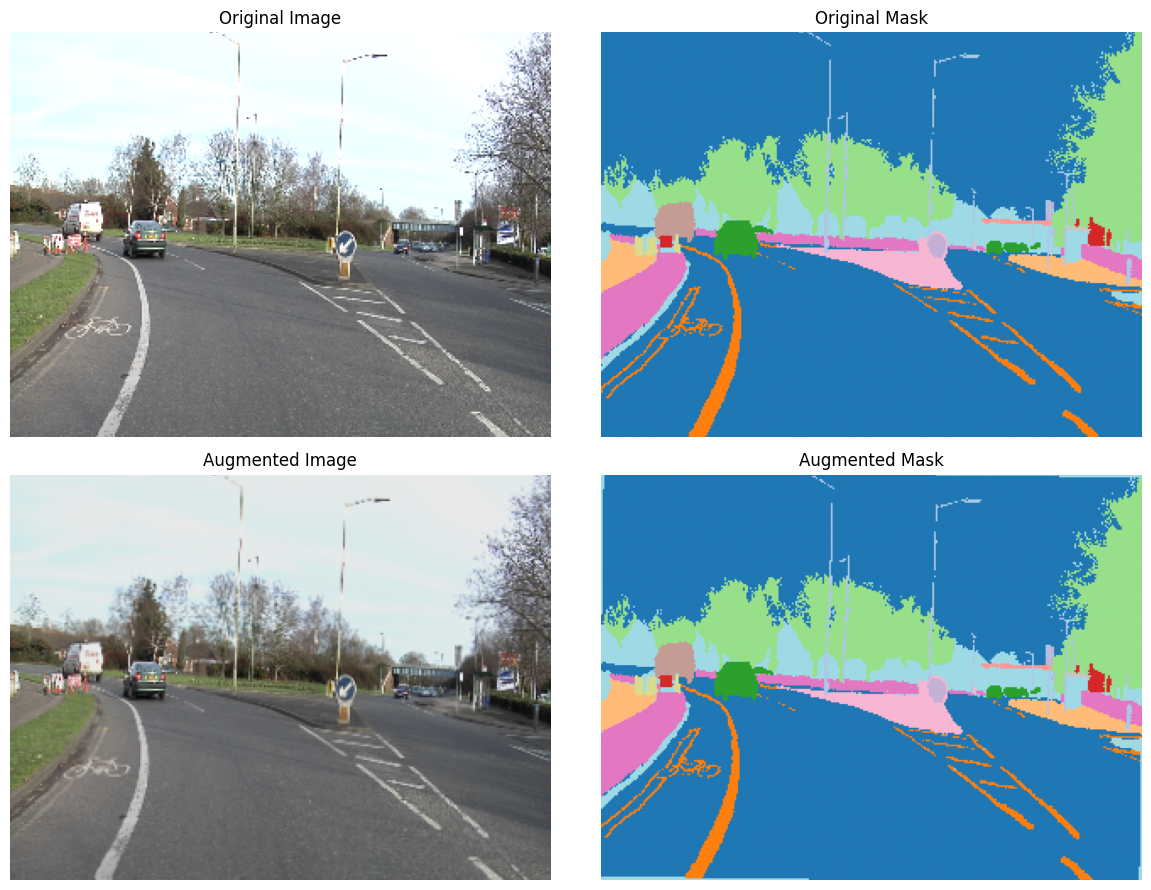

In [ ]:
# Visualize augmentation and label alignment
def denormalize_image(image_tensor):

    image = image_tensor.permute(1, 2, 0).numpy()

    image = image * IMAGE_STD + IMAGE_MEAN

    return np.clip(image, 0, 1)


fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Original sample without augmentation
original_dataset = CamVidImprovedDataset(
    train_df,
    image_size=IMAGE_SIZE,
    augment=False
)

original_image, original_mask = original_dataset[0]

# Augmented sample
augmented_image, augmented_mask = train_dataset[0]

axes[0, 0].imshow(denormalize_image(original_image))
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(
    original_mask.numpy(),
    cmap="tab20",
    vmin=0,
    vmax=28
)
axes[0, 1].set_title("Original Mask")

axes[1, 0].imshow(denormalize_image(augmented_image))
axes[1, 0].set_title("Augmented Image")

axes[1, 1].imshow(
    augmented_mask.numpy(),
    cmap="tab20",
    vmin=0,
    vmax=28
)
axes[1, 1].set_title("Augmented Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Data loaders and class weights

In [ ]:
# Create data loaders
TRAIN_NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=TRAIN_NUM_WORKERS,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=TRAIN_NUM_WORKERS,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=TRAIN_NUM_WORKERS,
    drop_last=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 51
Validation batches: 22
Test batches: 16


In [ ]:
# Validate a complete batch
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image min/max:", images.min().item(), images.max().item())
print("Mask IDs:", torch.unique(masks).tolist())

assert images.shape == (
    BATCH_SIZE, 3, IMAGE_HEIGHT, IMAGE_WIDTH
)

assert masks.shape == (
    BATCH_SIZE, IMAGE_HEIGHT, IMAGE_WIDTH
)

assert masks.dtype == torch.long

assert set(torch.unique(masks).tolist()).issubset(
    set(range(NUM_CLASSES)) | {IGNORE_INDEX}
)

print("DataLoader validation passed.")

Image batch shape: torch.Size([8, 3, 240, 320])
Mask batch shape: torch.Size([8, 240, 320])
Image dtype: torch.float32
Mask dtype: torch.int64
Image min/max: -2.1179039478302 2.640000104904175
Mask IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 26, 255]
DataLoader validation passed.


In [ ]:
# Calculate class weights and training pixels
def calculate_training_class_weights(dataframe):

    pixel_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64
    )

    for _, row in dataframe.iterrows():

        source_mask = cv2.imread(
            str(row["bluechannel_mask_path"]),
            cv2.IMREAD_UNCHANGED
        )

        if source_mask is None:
            raise FileNotFoundError(
                row["bluechannel_mask_path"]
            )

        if source_mask.ndim == 3:
            source_mask = source_mask[:, :, 0]

        model_mask = convert_source_mask_to_model_mask(
            source_mask
        )

        valid_pixels = model_mask[
            model_mask != IGNORE_INDEX
        ]

        pixel_counts += np.bincount(
            valid_pixels,
            minlength=NUM_CLASSES
        )

    frequencies = pixel_counts.astype(np.float64)

    valid_classes = frequencies > 0

    median_frequency = np.median(
        frequencies[valid_classes]
    )

    weights = np.ones(NUM_CLASSES, dtype=np.float64)

    weights[valid_classes] = np.sqrt(
        median_frequency / frequencies[valid_classes]
    )

    weights = np.clip(
        weights,
        CLASS_WEIGHT_MIN,
        CLASS_WEIGHT_MAX
    )

    # Normalize weights for numerical stability
    weights = weights / weights[valid_classes].mean()

    weights[~valid_classes] = 0.0

    return pixel_counts, weights.astype(np.float32)


train_pixel_counts, class_weights = (
    calculate_training_class_weights(train_df)
)

class_weights_df = pd.DataFrame({
    "class_name": active_classes_df["class_name"],
    "training_pixels": train_pixel_counts,
    "class_weight": class_weights
})

display(
    class_weights_df.sort_values(
        "class_weight",
        ascending=False
    ).round(4)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Class weights calculated.")

,class_name,training_pixels,class_weight
25,TrafficCone,14589,2.6888
24,Animal,871,2.6888
27,LaneMkgsNonDriv,22744,2.6888
26,MotorcycleScooter,48677,2.6888
18,CartLuggagePram,97333,2.3064
21,Child,127806,2.0128
13,SignSymbol,203105,1.5967
28,Bridge,218198,1.5404
22,Archway,308646,1.2952
20,Truck_Bus,551042,0.9693


Class weights calculated.


## 6. Implement U-Net with pretrained ResNet-18

In [ ]:
# Define convolution block
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [ ]:
# Define decoder block
class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):

        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)

In [ ]:
# Define U-Net and ResNet-18 encoder
class UNetResNet18(nn.Module):

    def __init__(
        self,
        num_classes=29,
        pretrained=True
    ):

        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT
            if pretrained else None
        )

        self.encoder = models.resnet18(
            weights=weights
        )

        # ResNet encoder
        self.stem_conv = self.encoder.conv1
        self.stem_bn = self.encoder.bn1
        self.stem_relu = self.encoder.relu
        self.maxpool = self.encoder.maxpool

        self.layer1 = self.encoder.layer1
        self.layer2 = self.encoder.layer2
        self.layer3 = self.encoder.layer3
        self.layer4 = self.encoder.layer4

        # Decoder
        self.dec4 = DecoderBlock(
            in_channels=512,
            skip_channels=256,
            out_channels=256
        )

        self.dec3 = DecoderBlock(
            in_channels=256,
            skip_channels=128,
            out_channels=128
        )

        self.dec2 = DecoderBlock(
            in_channels=128,
            skip_channels=64,
            out_channels=96
        )

        self.dec1 = DecoderBlock(
            in_channels=96,
            skip_channels=64,
            out_channels=64
        )

        # Final full-resolution refinement
        self.final_conv = ConvBlock(
            64,
            32
        )

        self.classifier = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        input_size = x.shape[2:]

        # Encoder
        stem = self.stem_relu(
            self.stem_bn(
                self.stem_conv(x)
            )
        )

        x = self.maxpool(stem)

        e1 = self.layer1(x)
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)

        # Decoder
        d4 = self.dec4(e4, e3)
        d3 = self.dec3(d4, e2)
        d2 = self.dec2(d3, e1)
        d1 = self.dec1(d2, stem)

        # Restore original image dimensions
        d1 = F.interpolate(
            d1,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        d1 = self.final_conv(d1)

        logits = self.classifier(d1)

        return logits

In [ ]:
# Initialize model
model = UNetResNet18(
    num_classes=NUM_CLASSES,
    pretrained=True
).to(DEVICE)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Model initialized successfully.")
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Device:", DEVICE)

Model initialized successfully.
Total parameters: 15,047,397
Trainable parameters: 15,047,397
Device: cuda


In [ ]:
# Validate the model forward pass
model.eval()

with torch.no_grad():

    sample_images, sample_masks = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(DEVICE)

    logits = model(sample_images)

    predictions = torch.argmax(
        logits,
        dim=1
    )

print("Input shape:", sample_images.shape)
print("Logits shape:", logits.shape)
print("Predictions shape:", predictions.shape)
print("Target shape:", sample_masks.shape)

assert logits.shape == (
    sample_images.shape[0],
    NUM_CLASSES,
    IMAGE_HEIGHT,
    IMAGE_WIDTH
)

assert predictions.shape == sample_masks.shape

print("U-Net ResNet-18 forward-pass validation passed.")

Input shape: torch.Size([8, 3, 240, 320])
Logits shape: torch.Size([8, 29, 240, 320])
Predictions shape: torch.Size([8, 240, 320])
Target shape: torch.Size([8, 240, 320])
U-Net ResNet-18 forward-pass validation passed.


## 7. Combined loss function

In [ ]:
# Define weighted CrossEntropy and Dice loss
class CombinedSegmentationLoss(nn.Module):

    def __init__(
        self,
        class_weights,
        ignore_index=255,
        dice_weight=1.0
    ):

        super().__init__()

        self.register_buffer(
            "class_weights",
            class_weights.clone().detach()
        )

        self.ignore_index = ignore_index
        self.dice_weight = dice_weight

        self.ce_loss = nn.CrossEntropyLoss(
            weight=self.class_weights,
            ignore_index=ignore_index
        )

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        # Exclude ignored pixels
        valid = targets != self.ignore_index

        safe_targets = targets.clone()
        safe_targets[~valid] = 0

        probabilities = torch.softmax(logits, dim=1)

        # One-hot ground truth
        one_hot = F.one_hot(
            safe_targets,
            num_classes=logits.shape[1]
        ).permute(0, 3, 1, 2).float()

        valid_mask = valid.unsqueeze(1).float()

        probabilities = probabilities * valid_mask
        one_hot = one_hot * valid_mask

        # Sum over batch and spatial dimensions
        intersection = (
            probabilities * one_hot
        ).sum(dim=(0, 2, 3))

        prediction_sum = probabilities.sum(
            dim=(0, 2, 3)
        )

        target_sum = one_hot.sum(
            dim=(0, 2, 3)
        )

        dice_score = (
            2.0 * intersection + 1e-6
        ) / (
            prediction_sum + target_sum + 1e-6
        )

        # Only include classes present in ground truth
        present_classes = target_sum > 0

        if present_classes.any():
            dice_loss = 1.0 - dice_score[present_classes].mean()
        else:
            dice_loss = logits.sum() * 0.0

        return ce + self.dice_weight * dice_loss

In [ ]:
# Initialize loss function
criterion = CombinedSegmentationLoss(
    class_weights=class_weights_tensor,
    ignore_index=IGNORE_INDEX,
    dice_weight=DICE_WEIGHT
).to(DEVICE)

print("Combined loss initialized.")
print("Weighted CrossEntropy + Dice")

Combined loss initialized.
Weighted CrossEntropy + Dice


In [ ]:
# Test loss function
model.eval()

with torch.no_grad():

    images, masks = next(iter(train_loader))

    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    logits = model(images)

    sample_loss = criterion(
        logits,
        masks
    )

print("Sample combined loss:", sample_loss.item())

assert torch.isfinite(sample_loss)

print("Loss validation passed.")

Sample combined loss: 4.4086079597473145
Loss validation passed.


## 8. Configure Training

In [ ]:
# Freeze encoder for initial warm up
def set_encoder_trainable(model, trainable):

    for parameter in model.encoder.parameters():
        parameter.requires_grad = trainable


WARMUP_EPOCHS = 3

set_encoder_trainable(
    model,
    trainable=False
)

print("Encoder frozen for initial warm-up.")

Encoder frozen for initial warm-up.


In [ ]:
# Initialize AdamW and separate learning rates
encoder_parameters = list(
    model.encoder.parameters()
)

decoder_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if not name.startswith("encoder.")
]

optimizer = optim.AdamW(
    [
        {
            "params": encoder_parameters,
            "lr": ENCODER_LR
        },
        {
            "params": decoder_parameters,
            "lr": DECODER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print("AdamW initialized.")
print("Encoder LR:", ENCODER_LR)
print("Decoder LR:", DECODER_LR)

AdamW initialized.
Encoder LR: 0.0001
Decoder LR: 0.001


In [ ]:
# Configure learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

best_val_miou = -1.0
epochs_without_improvement = 0

train_losses = []
val_losses = []
val_mious = []

print("Scheduler initialized.")

Scheduler initialized.


In [ ]:
# Prepare TPU aware data loaders
if DEVICE_TYPE == "TPU":

    import torch_xla.core.xla_model as xm

    import torch_xla.distributed.parallel_loader as pl

    def get_device_loader(loader):
        return pl.MpDeviceLoader(loader, DEVICE)

else:

    def get_device_loader(loader):
        return loader


train_device_loader = get_device_loader(train_loader)
val_device_loader = get_device_loader(val_loader)

print("Device loaders prepared.")
print("Execution device:", DEVICE_TYPE)

Device loaders prepared.
Execution device: GPU


## 9. Training and Evaluation functions

In [ ]:
# Training function
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()
    #if any(not p.requires_grad for p in model.encoder.parameters()):
    #  model.encoder.eval()

    total_loss = torch.zeros((), device=device)
    total_samples = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(logits, masks)

        loss.backward()

        if DEVICE_TYPE == "TPU":
            xm.optimizer_step(optimizer)
        else:
            optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.detach() * batch_size
        total_samples += batch_size

    if DEVICE_TYPE == "TPU":
        xm.mark_step()

    epoch_loss = (
        total_loss / total_samples
    ).item()

    return epoch_loss

In [ ]:
# Validation and loss function
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = torch.zeros((), device=device)
    total_samples = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            loss = criterion(logits, masks)

            batch_size = images.size(0)

            total_loss += loss * batch_size
            total_samples += batch_size

    if DEVICE_TYPE == "TPU":
        xm.mark_step()

    return (
        total_loss / total_samples
    ).item()

In [ ]:
# Calculate confusion matrix
def calculate_confusion_matrix(
    model,
    loader,
    device,
    num_classes
):

    model.eval()

    confusion = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64
    )

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            valid = masks != IGNORE_INDEX

            targets = masks[valid].cpu().numpy()
            preds = predictions[valid].cpu().numpy()

            encoded = (
                targets * num_classes + preds
            )

            batch_counts = np.bincount(
                encoded,
                minlength=num_classes * num_classes
            )

            confusion += batch_counts.reshape(
                num_classes,
                num_classes
            )

    if DEVICE_TYPE == "TPU":
        xm.mark_step()

    return confusion

In [ ]:
# Calculate segmentation matrix
def calculate_segmentation_metrics(
    confusion,
    class_names
):

    true_positive = np.diag(confusion)

    ground_truth_count = confusion.sum(axis=1)
    predicted_count = confusion.sum(axis=0)

    union = (
        ground_truth_count
        + predicted_count
        - true_positive
    )

    class_iou = np.divide(
        true_positive,
        union,
        out=np.full(len(class_names), np.nan),
        where=union > 0
    )

    class_accuracy = np.divide(
        true_positive,
        ground_truth_count,
        out=np.full(len(class_names), np.nan),
        where=ground_truth_count > 0
    )

    total_pixels = confusion.sum()

    pixel_accuracy = (
        true_positive.sum() / total_pixels
        if total_pixels > 0 else np.nan
    )

    mean_iou = np.nanmean(class_iou)

    mean_pixel_accuracy = np.nanmean(
        class_accuracy
    )

    class_metrics = pd.DataFrame({
        "class_name": class_names,
        "ground_truth_pixels": ground_truth_count,
        "predicted_pixels": predicted_count,
        "pixel_accuracy": class_accuracy,
        "iou": class_iou
    })

    supported_classes = int(
        np.sum(ground_truth_count > 0)
    )

    return {
        "pixel_accuracy": pixel_accuracy,
        "mean_pixel_accuracy": mean_pixel_accuracy,
        "mean_iou": mean_iou,
        "supported_classes": supported_classes,
        "class_metrics": class_metrics,
        "confusion_matrix": confusion
    }

## 10. Training the improved model

In [ ]:
# Training loop
for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # Unfreeze encoder after warm-up
    if epoch == WARMUP_EPOCHS:

        set_encoder_trainable(
            model,
            trainable=True
        )

        print("\nEncoder unfrozen. Fine-tuning started.")

    # Training
    train_loss = train_one_epoch(
        model,
        train_device_loader,
        criterion,
        optimizer,
        DEVICE
    )

    # Validation loss
    val_loss = validate_one_epoch(
        model,
        val_device_loader,
        criterion,
        DEVICE
    )

    # Validation mIoU
    val_confusion = calculate_confusion_matrix(
        model,
        val_device_loader,
        DEVICE,
        NUM_CLASSES
    )

    val_metrics = calculate_segmentation_metrics(
        val_confusion,
        active_classes_df["class_name"].tolist()
    )

    val_miou = val_metrics["mean_iou"]

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_mious.append(val_miou)

    # Update scheduler
    scheduler.step(val_miou)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val mIoU: {val_miou:.4f} "
        f"Classes: {val_metrics['supported_classes']} "
        f"Time: {epoch_time:.1f}s"
    )

    # Save best model
    if val_miou > best_val_miou:

        best_val_miou = val_miou
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_miou": best_val_miou,
            "val_loss": val_loss,
            "num_classes": NUM_CLASSES,
            "class_names": active_classes_df[
                "class_name"
            ].tolist(),
            "source_id_to_model_id": SOURCE_ID_TO_MODEL_ID,
            "image_size": IMAGE_SIZE,
            "image_mean": IMAGE_MEAN.tolist(),
            "image_std": IMAGE_STD.tolist(),
            "ignore_index": IGNORE_INDEX
        }

        if DEVICE_TYPE == "TPU":
            xm.save(checkpoint, str(BEST_MODEL_PATH))
        else:
            torch.save(checkpoint, BEST_MODEL_PATH)

        print("  Best checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch + 1}."
        )

        break

print("\nImproved training completed.")
print("Best validation mIoU:", best_val_miou)
print("Checkpoint:", BEST_MODEL_PATH)

Epoch [1/40] Train Loss: 2.1877 Val Loss: 2.0239 Val mIoU: 0.1673 Classes: 26 Time: 139.6s
  Best checkpoint saved.
Epoch [2/40] Train Loss: 1.8158 Val Loss: 1.8029 Val mIoU: 0.1958 Classes: 26 Time: 57.5s
  Best checkpoint saved.
Epoch [3/40] Train Loss: 1.6175 Val Loss: 1.7194 Val mIoU: 0.1990 Classes: 26 Time: 58.9s
  Best checkpoint saved.

Encoder unfrozen. Fine-tuning started.
Epoch [4/40] Train Loss: 1.4809 Val Loss: 1.6638 Val mIoU: 0.2110 Classes: 26 Time: 58.7s
  Best checkpoint saved.
Epoch [5/40] Train Loss: 1.3460 Val Loss: 1.5999 Val mIoU: 0.2327 Classes: 26 Time: 63.8s
  Best checkpoint saved.
Epoch [6/40] Train Loss: 1.2473 Val Loss: 1.5799 Val mIoU: 0.2251 Classes: 26 Time: 62.3s
Epoch [7/40] Train Loss: 1.1463 Val Loss: 1.5738 Val mIoU: 0.2421 Classes: 26 Time: 56.9s
  Best checkpoint saved.
Epoch [8/40] Train Loss: 1.1060 Val Loss: 1.4976 Val mIoU: 0.2363 Classes: 26 Time: 62.2s
Epoch [9/40] Train Loss: 1.0080 Val Loss: 1.5136 Val mIoU: 0.2338 Classes: 26 Time: 56.8s

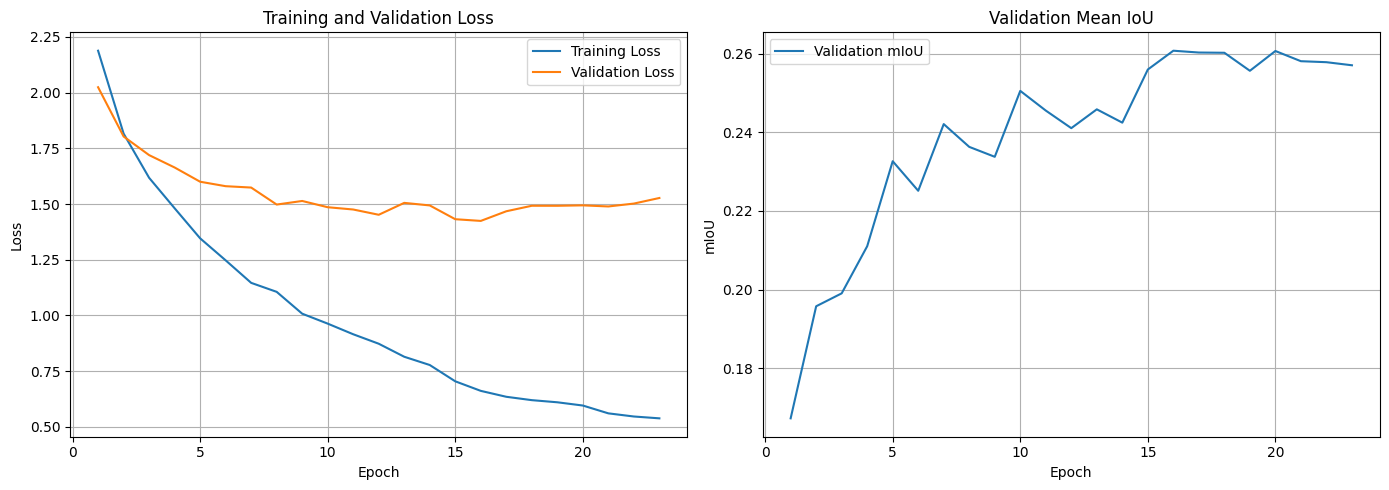

In [ ]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(train_losses) + 1)

axes[0].plot(
    epochs,
    train_losses,
    label="Training Loss"
)

axes[0].plot(
    epochs,
    val_losses,
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs,
    val_mious,
    label="Validation mIoU"
)

axes[1].set_title("Validation Mean IoU")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 11. Final evaluation

In [ ]:
# Load the best checkpoint
if DEVICE_TYPE == "TPU":
    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )
else:
    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best checkpoint loaded.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation mIoU:", checkpoint["best_val_miou"])

Best checkpoint loaded.
Best epoch: 16
Best validation mIoU: 0.2607671627108245


In [ ]:
# Evaluate on the test set
test_device_loader = get_device_loader(test_loader)

test_confusion = calculate_confusion_matrix(
    model,
    test_device_loader,
    DEVICE,
    NUM_CLASSES
)

test_metrics = calculate_segmentation_metrics(
    test_confusion,
    active_classes_df["class_name"].tolist()
)

print("Test Pixel Accuracy:",
      round(test_metrics["pixel_accuracy"], 4))

print("Test Mean Pixel Accuracy:",
      round(test_metrics["mean_pixel_accuracy"], 4))

print("Test Mean IoU:",
      round(test_metrics["mean_iou"], 4))

print(
    "Classes with ground-truth support:",
    test_metrics["supported_classes"],
    "/",
    NUM_CLASSES
)

display(
    test_metrics["class_metrics"].sort_values(
        "iou",
        ascending=False
    ).round(4)
)

Test Pixel Accuracy: 0.6667
Test Mean Pixel Accuracy: 0.3323
Test Mean IoU: 0.1996
Classes with ground-truth support: 22 / 29


,class_name,ground_truth_pixels,predicted_pixels,pixel_accuracy,iou
0,Road,1539185,1539690,0.8886,0.7994
4,Building,1871481,2452602,0.9446,0.6916
5,Sidewalk,418040,571866,0.8927,0.6051
1,Sky,1926256,931899,0.4796,0.4777
8,Tree,1506841,2004589,0.7458,0.4707
10,TrafficLight,29548,17069,0.4510,0.4003
3,LaneMkgsDriv,81258,44560,0.4087,0.3586
7,Pedestrian,83704,125740,0.5239,0.2648
6,Car,567821,180994,0.2703,0.2578
11,Wall,206582,69002,0.1831,0.1591


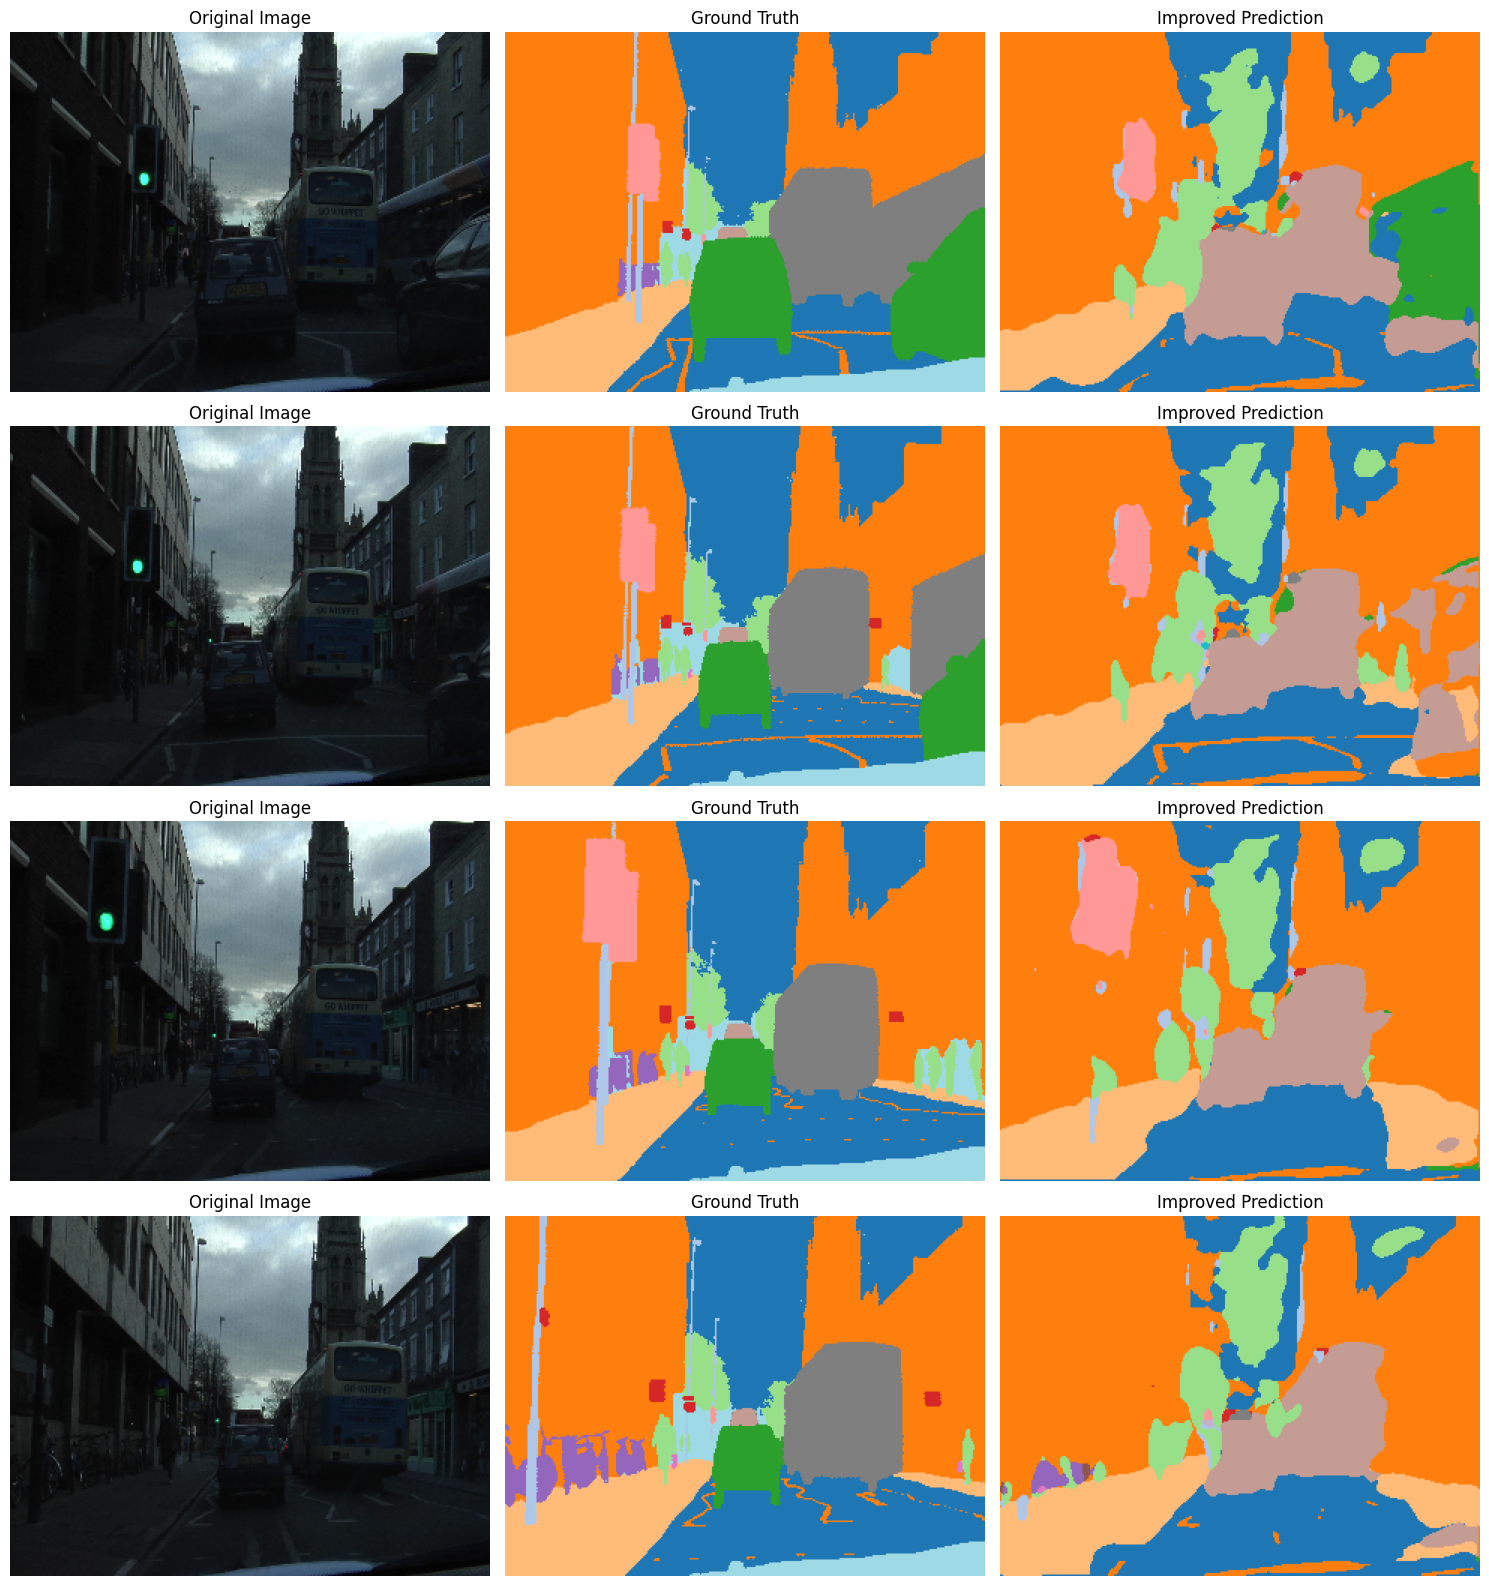

In [ ]:
#Visualize improve prediction
images, masks = next(iter(test_loader))

model.eval()

with torch.no_grad():

    logits = model(
        images.to(DEVICE)
    )

    predictions = torch.argmax(
        logits,
        dim=1
    ).cpu()

fig, axes = plt.subplots(4, 3, figsize=(15, 16))

for i in range(4):

    axes[i, 0].imshow(
        denormalize_image(images[i])
    )

    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        masks[i].numpy(),
        cmap="tab20",
        vmin=0,
        vmax=28
    )

    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        predictions[i].numpy(),
        cmap="tab20",
        vmin=0,
        vmax=28
    )

    axes[i, 2].set_title("Improved Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

Normalized confusion matrix calculated.
Matrix shape: (29, 29)
Classes with ground-truth support: 22 / 29


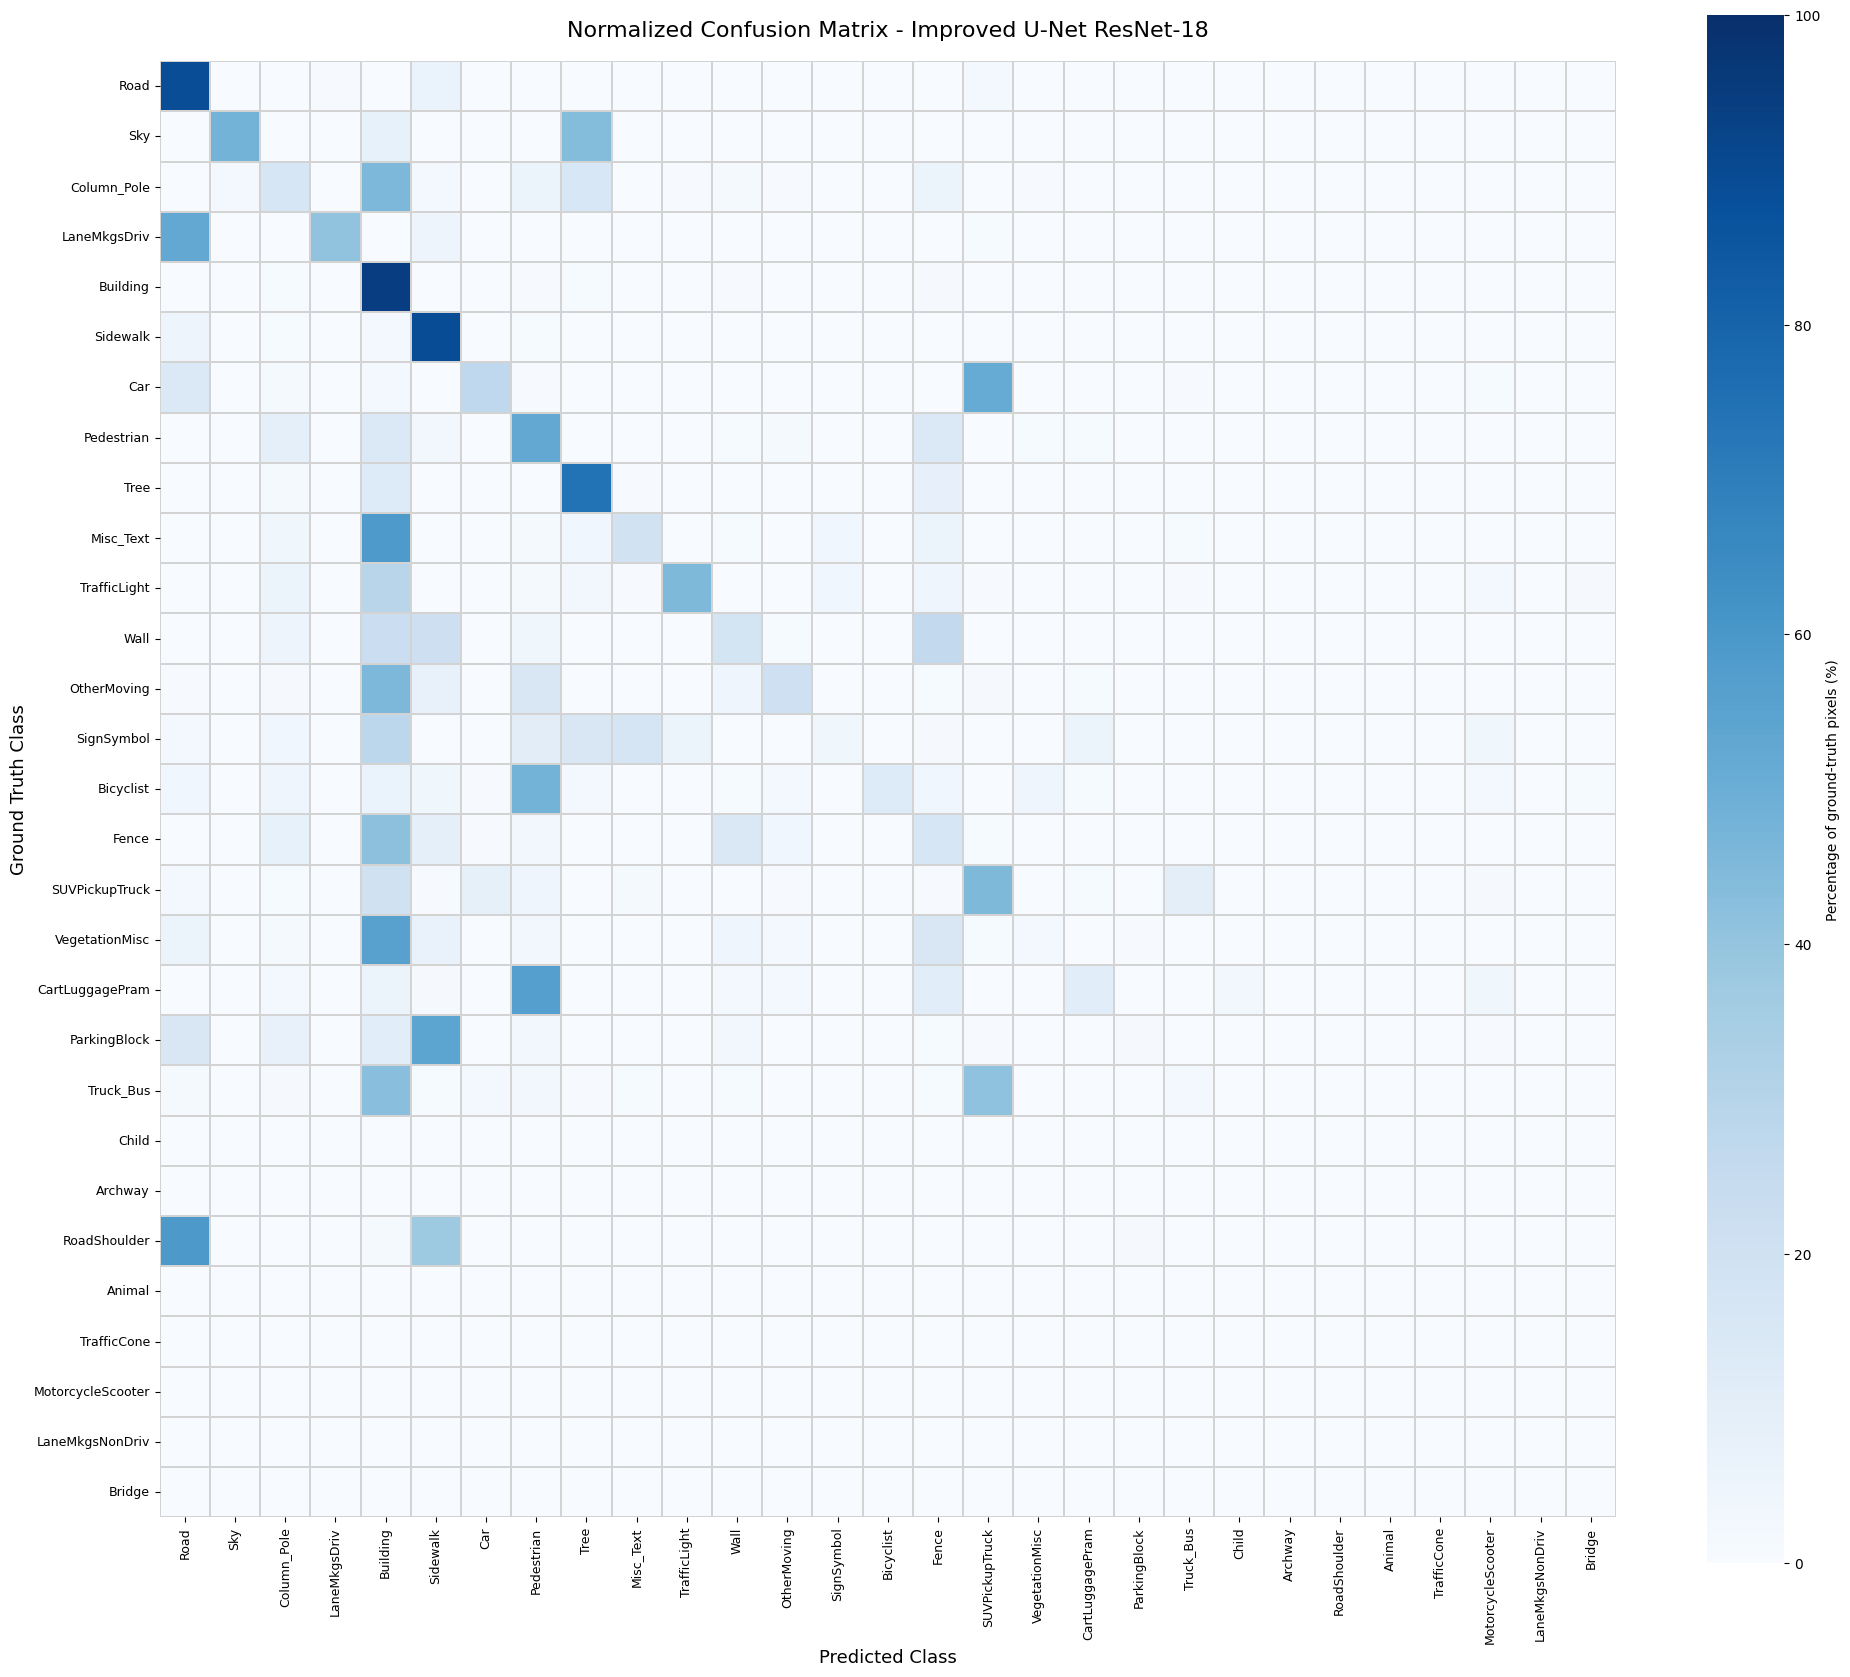


Raw confusion matrix:


,Road,Sky,Column_Pole,LaneMkgsDriv,Building,Sidewalk,Car,Pedestrian,Tree,Misc_Text,...,ParkingBlock,Truck_Bus,Child,Archway,RoadShoulder,Animal,TrafficCone,MotorcycleScooter,LaneMkgsNonDriv,Bridge
Road,1367788,0,944,10604,4175,104481,4895,1489,0,0,...,1657,12,0,0,0,0,0,308,0,0
Sky,0,923922,2698,0,150977,0,8,2,847071,711,...,0,51,0,110,0,0,0,45,0,21
Column_Pole,43,1827,12861,0,35277,2099,244,4477,12105,84,...,30,149,12,0,0,0,0,270,0,56
LaneMkgsDriv,42539,0,21,33210,144,4361,72,66,0,0,...,40,0,0,0,0,0,0,11,0,0
Building,144,851,16752,0,1767802,3348,2314,11364,14895,3654,...,9,2990,104,14,0,0,0,664,0,577
Sidewalk,22161,0,4328,232,10254,373194,281,3917,0,0,...,1112,1,3,0,0,0,0,76,0,2
Car,80407,14,9827,127,12166,1452,153472,2936,210,230,...,1191,4248,13,0,0,0,0,4738,0,552
Pedestrian,114,1,7976,0,12031,2456,68,43855,103,0,...,0,5,304,0,0,0,0,262,0,19
Tree,73,4944,24029,0,197962,96,860,2584,1123786,6519,...,30,1061,288,135,0,0,0,2525,0,1603
Misc_Text,0,0,1879,0,27024,0,12,863,1689,8782,...,0,437,0,0,0,0,0,37,0,36


In [ ]:
# Generate normalized confusion matrix

# ============================================================
# CELL 40: NORMALIZED CONFUSION MATRIX
# Notebook 06 - Improved U-Net with ResNet-18
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

# Initialize confusion matrix
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

with torch.no_grad():
    for images, masks in test_device_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        # Model predictions
        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        # Exclude ignored pixels
        valid_pixels = masks != IGNORE_INDEX

        true_labels = masks[valid_pixels].long()
        predicted_labels = predictions[valid_pixels].long()

        # Accumulate confusion matrix
        encoded = true_labels * NUM_CLASSES + predicted_labels

        batch_confusion = torch.bincount(
            encoded,
            minlength=NUM_CLASSES * NUM_CLASSES
        )

        batch_confusion = batch_confusion.reshape(
            NUM_CLASSES, NUM_CLASSES
        )

        confusion += batch_confusion.cpu().numpy()

# TPU execution synchronization
if DEVICE_TYPE == "TPU":
    xm.mark_step()

# ------------------------------------------------------------
# Normalize by ground-truth class (row-wise normalization)
# ------------------------------------------------------------

row_totals = confusion.sum(axis=1, keepdims=True)

normalized_confusion = np.divide(
    confusion.astype(np.float64),
    row_totals,
    out=np.zeros_like(confusion, dtype=np.float64),
    where=row_totals != 0
)

# Class names in model output order
class_names = active_classes_df["class_name"].tolist()

# Convert to percentage
normalized_confusion_percent = normalized_confusion * 100

# Create DataFrame for inspection/export
confusion_df = pd.DataFrame(
    normalized_confusion_percent,
    index=class_names,
    columns=class_names
)

print("Normalized confusion matrix calculated.")
print("Matrix shape:", confusion_df.shape)
print("Classes with ground-truth support:",
      int((row_totals.flatten() > 0).sum()), "/", NUM_CLASSES)

# ------------------------------------------------------------
# Plot heatmap
# ------------------------------------------------------------

plt.figure(figsize=(20, 17))

sns.heatmap(
    confusion_df,
    cmap="Blues",
    vmin=0,
    vmax=100,
    square=True,
    linewidths=0.2,
    linecolor="lightgray",
    cbar_kws={
        "label": "Percentage of ground-truth pixels (%)"
    }
)

plt.title(
    "Normalized Confusion Matrix - Improved U-Net ResNet-18",
    fontsize=16,
    pad=18
)

plt.xlabel("Predicted Class", fontsize=13)
plt.ylabel("Ground Truth Class", fontsize=13)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

# Display raw confusion matrix for further analysis
print("\nRaw confusion matrix:")
display(pd.DataFrame(
    confusion,
    index=class_names,
    columns=class_names
))


## Interpretation and Analysis of the Normalized Confusion Matrix

The normalized confusion matrix provides a class-level assessment of the improved U-Net with ResNet-18 semantic segmentation model. Rows represent ground-truth classes, while columns represent predicted classes. Each row is normalized by the number of ground-truth pixels belonging to that class.

### 1. Strong performance on dominant scene classes

The model demonstrates strong recognition of major road-scene components, achieving pixel accuracies of 88.86% for Road, 94.46% for Building and 89.27% for Sidewalk. Tree also achieves reasonable recognition at 74.58%.

These results indicate that the model has learned useful spatial and semantic representations for large, visually consistent scene regions.

### 2. Confusion between visually similar classes

Several classes exhibit significant misclassification patterns:

- Sky and Tree: Approximately 44% of ground-truth Sky pixels are classified as Tree.
- LaneMkgsDriv and Road: Approximately 52% of LaneMkgsDriv pixels are classified as Road.
- Column_Pole and Building: Approximately 46% of Column_Pole pixels are classified as Building.
- Bicyclist and Pedestrian: The model frequently confuses these two categories.
- Truck_Bus and Building: A substantial proportion of Truck_Bus pixels are incorrectly classified as Building.

These patterns suggest difficulties in distinguishing visually similar classes and preserving accurate object boundaries.

### 3. Overprediction and underprediction

The model overpredicts certain classes, particularly Building, Tree, SUVPickupTruck and Fence. Conversely, it underpredicts classes such as Sky, Car and Truck_Bus.

This indicates that the model still exhibits class-specific prediction bias, despite the use of class-weighted Cross-Entropy and Dice loss.

### 4. Challenges with small and rare objects

The model performs poorly on several less frequent classes, including SignSymbol, ParkingBlock and VegetationMisc. Thin structures and small objects remain difficult to segment accurately.

The limited number of training pixels for these categories, together with their visual similarity to surrounding objects, likely contributes to the observed errors.

### 5. Test-set class coverage limitation

Only 22 of the 29 semantic classes have ground-truth pixel support in the test dataset. Consequently, the performance of the remaining seven classes cannot be fully evaluated on this test split.

Four unsupported classes receive false-positive predictions, while three receive no predictions. Additional evaluation data containing these categories would be necessary to establish their generalization performance.

### Overall conclusion

The normalized confusion matrix confirms that the improved U-Net with pretrained ResNet-18 encoder has learned the dominant semantic structure of road scenes effectively. However, it continues to struggle with visually similar categories, small objects, thin structures and underrepresented classes.

The findings demonstrate the benefits of transfer learning and combined segmentation loss while highlighting the continuing challenges of class imbalance, object boundary localization and generalization across unseen driving sequences.